This notebook is an extension of what I learnd from Jed's class (see his notebook https://github.com/cu-numcomp)

In [1]:
using Plots
using LinearAlgebra
using SparseArrays
using FastGaussQuadrature
using NLsolve
using Test

In [2]:
default(linewidth=3)

function my_spy(A)
    cmax = norm(vec(A), Inf)
    s = max(1, ceil(120 / size(A, 1)))
    spy(A, marker=(:square, s), c=:diverging_rainbow_bgymr_45_85_c67_n256, clims=(-cmax, cmax))
end

my_spy (generic function with 1 method)

## Ciarlet (1978) definition

A **finite element** is a triple $(K, P, N)$ where
* $K$ is a bounded domain with piecewise smooth boundary
* $P = \{p_j\}_1^k$ is a finite-dimensional function space over $K$ ("prime basis")
* $N = \{n_i\}_1^k$ is a basis for the dual space ("nodes")

It is common for nodes to be pointwise evaluation
$$ \langle n_i, p_j \rangle = p_j(x_i) $$

We use **Legendre polynomials** as a prime basis. 

In [3]:
function vander_legendre_deriv(x, k=nothing)
    if isnothing(k)
        k = length(x) # Square matrix by default
    end
    m = length(x)
    Q = ones(m, k)
    dQ = zeros(m, k)
    Q[:, 2] = x
    dQ[:, 2] .= 1
    for n in 1:k-2
        Q[:, n+2] = ((2*n + 1) * x .* Q[:, n+1] - n * Q[:, n]) / (n + 1)
        dQ[:, n+2] = (2*n + 1) * Q[:,n+1] + dQ[:,n]
    end
    Q, dQ
end

vander_legendre_deriv (generic function with 2 methods)

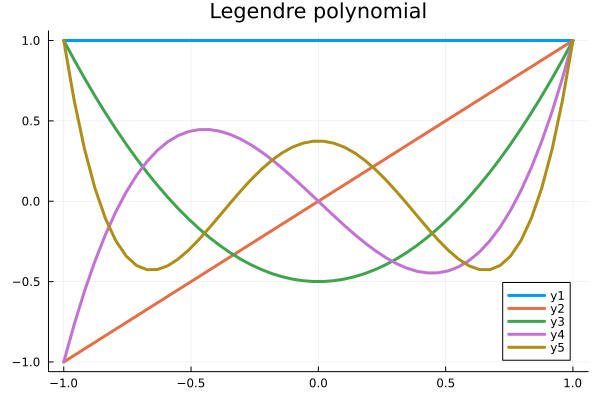

In [4]:
x = LinRange(-1, 1, 50)
P, dP = vander_legendre_deriv(x, 5)
plot(x, P, title = "Legendre polynomial",)

# Prime to nodal basis
(see sec 4.3 of fenics book)

We use the prime basis $\{ p \}_{i=1}^n$ (here legendre polynomials) that spans the finite element space $P$ to construct nodal basis $\phi_j$

$$
\phi_j = \sum_{k=1}^n \alpha_{jk} p_k
$$

A **nodal basis** $\{ \phi_j(x) \}$ is one that satisfies
$ n_i(\phi_j) = \delta_{ij} . $

$$
\delta_{ij} = \sum_{k=1}^n n_i(\alpha_{jk} p_k) =  \sum_{k=1}^n \alpha_{jk} n_i(p_k) = \sum_{k=1}^n \alpha_{jk} V_{ik}
$$

in matrix notation
$$
I = V \alpha^T \Longrightarrow  \alpha = V^{-T}
$$

We write $\phi_j$ as (since we multiply $p$ from the right we removed the transpose),
$$ \phi_j(x) = \sum_k p_k(x) (V^{-1})_{k,j} . $$

and the derivative of nodal basis is
$$ d\phi_j(x) = \sum_k dp_k(x) (V^{-1})_{k,j} . $$

# 1D element [-1, 1] with evenly spaced nodes

For higher order we will have ill-conditioned problem if we use evenly spaced nodes. See figures below.

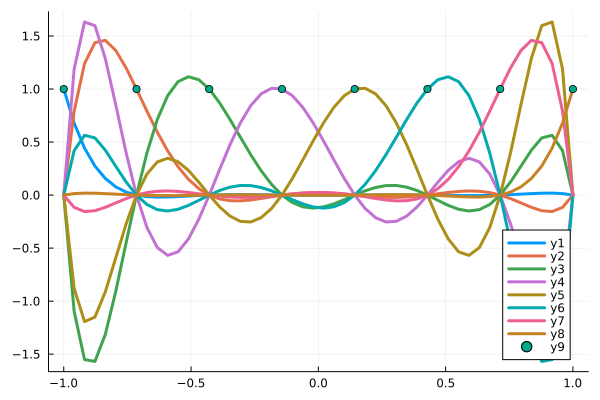

In [5]:
k = 8
xn = LinRange(-1, 1, k)
V, _ = vander_legendre_deriv(xn)
xx = LinRange(-1, 1, 50)
Pxx, _ = vander_legendre_deriv(xx, k) # p_k(x) computed at 50 points
Pn = Pxx / V  # \phi(x) = p * V^{-1} nodal basis
plot(xx, Pn)
scatter!(xn, one.(xn))

# 1D element [-1, 1] with nodes located at Lobatto points

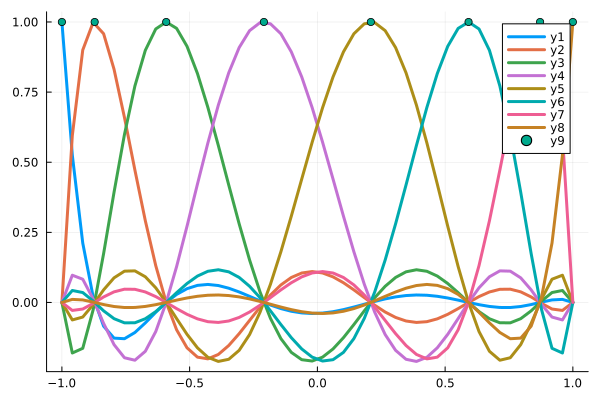

In [6]:
xn, _ = gausslobatto(k)
V, _ = vander_legendre_deriv(xn)
Pn = Pxx / V
plot(xx, Pn)
scatter!(xn, one.(xn))

# Galerkin method: $L^2$ projection on ref element [-1,1]

A nice test problem that doesn't require derivatives or boundary conditions:
Find $u \in \mathcal V_h$ such that
$$ \int_{-1}^1 v(x) \big[ u(x) - f(x) \big] = 0, \quad \forall v \in \mathcal V_h$$

In [7]:
function febasis(P, Q, Qmode)
    x, _ = gausslobatto(P)
    if Qmode == "GAUSS"
        q, w = gausslegendre(Q)
    elseif Qmode == "GLL"
        q, w = gausslobatto(Q)
    else
        error("Qmode error! Choose GAUSS or GLL Quadrature points!");
    end
    V, _ = vander_legendre_deriv(x)
    Bp, Dp = vander_legendre_deriv(q, P)
    B = Bp / V
    D = Dp / V
    x, q, w, B, D
end

function L2_galerkin(P, Q, f, Qmode)
    x, q, w, B, _ = febasis(P, Q, Qmode)
    A = B' * diagm(w) * B  # v^T * u
    rhs = B' * diagm(w) * f.(q)  # v^T * f
    # Jacobi-preconditioned mass matrix
    #@show cond(A)
    #@show cond(diagm(1 ./diag(A))*A)
    u = (diagm(1 ./diag(A))*A) \ (diagm(1 ./diag(A))*rhs)
    #u = A \ rhs

    x, u
end

L2_galerkin (generic function with 1 method)

In [8]:
_, _, _, B, _ = febasis(2, 3, "GAUSS")
B

3×2 Matrix{Float64}:
 0.887298  0.112702
 0.5       0.5
 0.112702  0.887298

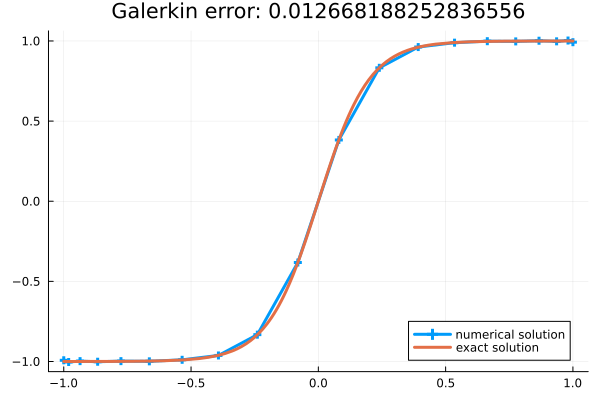

In [9]:
f(x) = tanh(5*x)
x, u = L2_galerkin(20, 20, f, "GAUSS")
err = u - f.(x)
plot(x, u, marker=:auto, legend=:bottomright, label = "numerical solution")
plot!(f, title="Galerkin error: $(norm(err))", label="exact solution")

### Try few quadrature points and see condition numbers of A ($P > Q$) 

# Convergence of the Galerkin method for L2 projection

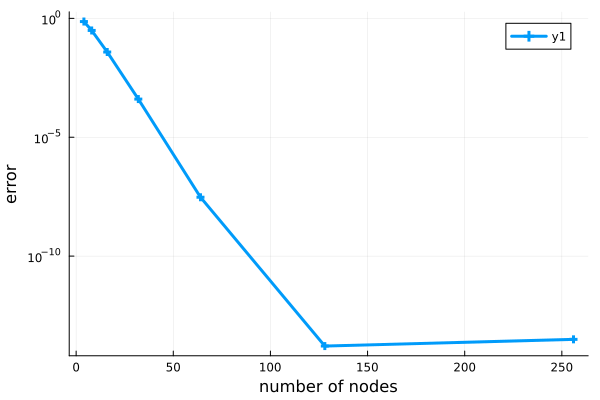

In [10]:
ns = 2 .^ (2:8)
function L2_error(n, Qmode)
    x, u = L2_galerkin(n, n, f, Qmode)
    norm(u - f.(x))
end
plot(ns, L2_error.(ns,"GAUSS"), marker=:auto, yscale=:log10, xlabel="number of nodes", ylabel="error")

# Test Grad mode on the reference element

In [11]:
f(x) = @. x^2
grad_f(x) = @. 2*x

grad_f (generic function with 1 method)

In [12]:
P, Q = 2, 3
x, q, w, BL, _ = febasis(P, Q, "GLL")
x, q, w, _, Du = febasis(Q, Q, "GAUSS")
x, q, w, Bx, _ = febasis(P, Q, "GAUSS")

X = [-1, 1]
X_q = BL*X
U = f(X_q[:,1])
Gh = Du*U;
X_q1 = Bx * X;
Ge = grad_f(X_q1);
@test Gh ≈ Ge

Test Passed

# Galerkin method for Poisson on ref element [-1,1]

$$ \int_{\Omega} \nabla v \cdot \kappa \cdot \nabla u = \int_{\Omega} v f, \forall v$$

In [13]:
function poisson_galerkin(P, Q, kappa, f, Qmode)
    x, q, w, B, D = febasis(P, Q, Qmode)
    A = D' * diagm(w .* kappa.(q)) * D
    rhs = B' * diagm(w) * f.(q)
    # Dirichlet Boundary conditions
    rhs[[1,end]] .= 0
    A[1, :] .= 0
    A[1, 1] = 1
    A[end, :] .= 0
    A[end, end] = 1
    u = A \ rhs
    x, u
end

poisson_galerkin (generic function with 1 method)

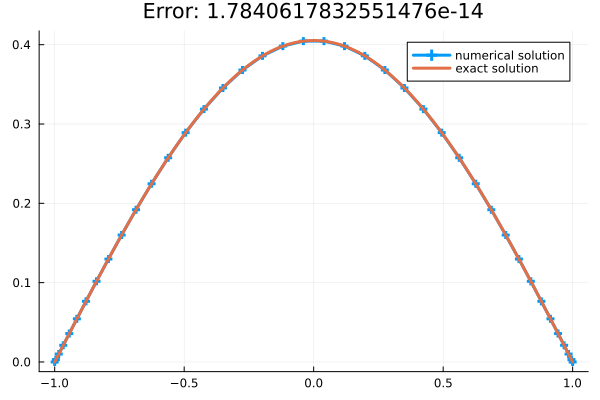

In [14]:
# case kappa=1
f(x) = cos(x*pi/2)
x, u = poisson_galerkin(40, 40, one, f, "GAUSS")
plot(x, u, marker=:auto, label = "numerical solution")
uexact(x) = cos(x*pi/2) * (2/pi)^2
plot!(uexact, title="Error: $(norm(u - uexact.(x)))", label = "exact solution")

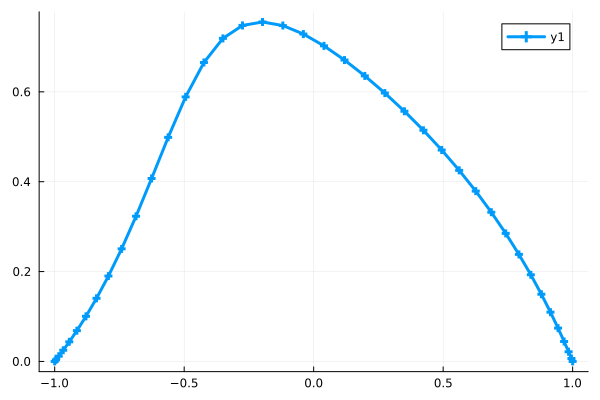

In [15]:
# arbitrary kappa
kappa(x) = 0.6 .+ 0.4 * sin.(pi*x)
x, u = poisson_galerkin(40, 40, kappa, x -> cos(x*pi/2), "GAUSS")
plot(x, u, marker=:auto)

### if we apply Neumann on both sides we get singular matrix

Because we have function that second derivative is zero and the first derivative is zero on the boundaries, so we get constant function. So we need at least one boundary condition.

In [16]:
x, q, w, B, D = febasis(7, 10, "GAUSS")
A = D' * diagm(w .* kappa.(q)) * D
@show norm(A - A')
eigvals(A)

norm(A - A') = 1.572130924749293e-15


7-element Vector{Float64}:
 -4.1417059836029554e-16
  0.2113042648119082
  1.3866142540744653
  3.2701200000673114
  6.853818219483836
 10.692355373099762
 14.545787888462762

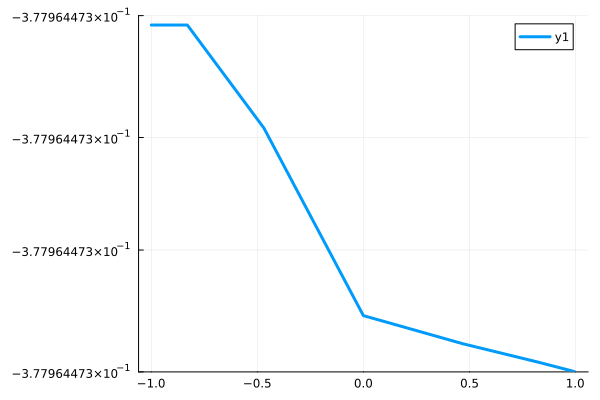

GKS: Possible loss of precision in routine SET_WINDOW


In [17]:
L, X = eigen(A)
plot(x, X[:,1])

# Convergence of the Galerkin method for Poisson

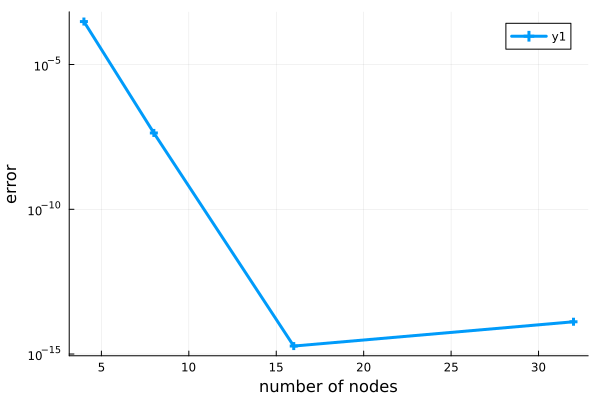

In [18]:
ns = 2 .^ (2:5)
function L2_error(n, Qmode)
    x, u = poisson_galerkin(n, n, one, f, Qmode)
    norm(u - uexact.(x))
end
plot(ns, L2_error.(ns, "GAUSS"), marker=:auto, yscale=:log10, xlabel="number of nodes", ylabel="error")

# Combine both on one element [xL,xR]

We solve

$$
\kappa \nabla^2 u + u = f
$$

Weak form

$$
\int v \nabla u \cdot n - \int \nabla v \kappa \nabla u + \int v u = \int v f
$$


We need to update each row of $D = \frac{\partial v}{\partial X}$ by jacobian $dX/dx$.

In [19]:
function general_galerkin(P, Q, kappa, f, Qmode; xL=0, xR=1)
    x, q, w, B, D = febasis(P, Q, Qmode)
    
    x = (xL + xR)/2 .+ (xR - xL)/2*x
    q = (xL + xR)/2 .+ (xR - xL)/2*q
    w = (xR - xL)/2 * w
    dXdx = ones(Q) * 2 / (xR - xL)
    K = (D' .* dXdx) * diagm(w .* kappa.(q)) * (dXdx .* D)
    M = B' * diagm(w) * B  # v^T * u
    rhs = B' * diagm(w) * f.(q)
    
    A = M - K
    # Dirichlet Boundary conditions
    rhs[[1,end]] .= 0
    A[1, :] .= 0
    A[1, 1] = 1
    A[end, :] .= 0
    A[end, end] = 1
    u = A \ rhs
    x, u
end

general_galerkin (generic function with 1 method)

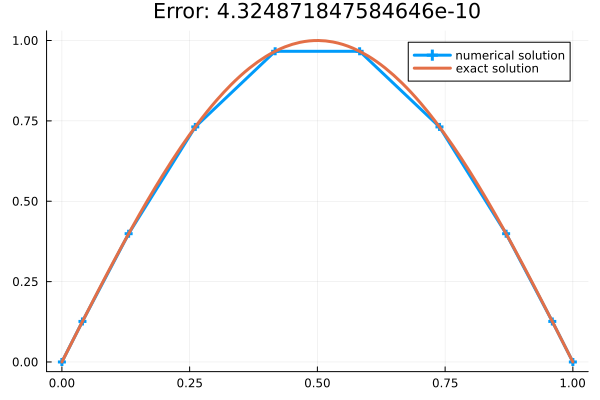

In [20]:
# case kappa=1
P = 10
Q = 10
f(x) = (1-pi^2) * sin(x*pi)
x, u = general_galerkin(P, Q, one, f, "GAUSS")
plot(x, u, marker=:auto, label = "numerical solution")
uexact(x) = sin(x*pi)
plot!(uexact, title="Error: $(norm(u - uexact.(x)))", label = "exact solution")

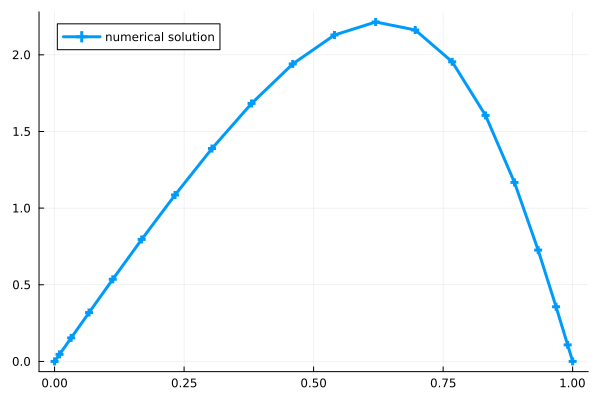

In [21]:
# arbitrary kappa
P = 20
Q = 20
kappa(x) = 0.6 .+ 0.4 * cos.(pi*x)
x, u = general_galerkin(P, Q, kappa, f, "GAUSS")
plot(x, u, marker=:auto, label = "numerical solution")

# <font color='red'> Multiple Elements: Define connectivity for Assembly

In [22]:
function GetConnectivity(P, nelx)
    """This function returns the connectivity array

    1----2----3----4----5
    
    local numbering of one element is

    1---...----P


    Input:
    ------
    nelx: number of element in x direction start from 1 
    Output:
    ------
    IEN: connectivity array of size P x () based on node numbering
    We need IENn to find the coordinate of nodes in assembly
    """
    # number of element
    num_elem = nelx
    # number of nodes in x-direction
    nodex = nelx + 1
    IEN = zeros(Int64, P,num_elem)
    for e=1:nelx
        for i=1:P 
            IEN[i,e] = i + (e-1)*(P-1)
        end
    end

    return IEN
end

function GetElementRestriction(IEN, e)
    """
    This function is map between local to global dof or element restriction operator.
    We use this function to scatter the local vector or matrix
    to global vector or matrix in assembly process
    """
    global_dof = maximum(IEN)
    # local dof number
    P = size(IEN,1)
    temp = zeros(Int64, P, 1)
    
    temp[:,1] = IEN[:,e]
    # element restriction operator
    L = spzeros(P, global_dof)
    for i=1:P
        L[i, IEN[i,e] ] = 1
    end

    return L 
end

GetElementRestriction (generic function with 1 method)

In [23]:
function GetFESolution(P, Q, kappa, f, Qmode, IEN; a=0, b=1)

    # coordinate, quadrature, and basis on reference element [-1,1]
    x_ref, q_ref, w_ref, B, D = febasis(P, Q, Qmode)

    num_elem = size(IEN,2)
    global_dof = maximum(IEN)
    F = zeros(global_dof, 1)
    A = zeros(global_dof,global_dof)
    # Divide domain [a,b] to num_elem
    x = LinRange(a, b, num_elem+1)
    # Store nodal coordinate in xn
    xn = Float64[]
    
    for e=1:num_elem
        # Get coordinate of the end nodes of each element
        xL, xR = x[e:e+1]
        # Nodal coordinate of each element
        xe = (xL + xR)/2 .+ (xR - xL)/2 * x_ref[1+(e>1):end]
        # Store nodal coordinates
        append!(xn, xe)
        # Update quadrature
        q = (xL + xR)/2 .+ (xR - xL)/2 * q_ref
        w = (xR - xL)/2 * w_ref
        # Jacobian
        dXdx = ones(Q) * 2 / (xR - xL)
        # Local operators
        Ke = (D' .* dXdx) * diagm(w .* kappa.(q)) * (dXdx .* D)
        Me = B' * diagm(w) * B  # v^T * u
        Fe = B' * diagm(w) * f.(q)
        E = GetElementRestriction(IEN, e)
        
        Ae = Me - Ke
        # Assemble
        A = A + E' * Ae * E
        F = F + E' * Fe

    end
    
    # Dirichlet Boundary conditions
    F[[1,end]] .= 0
    A[1, :] .= 0
    A[1, 1] = 1
    A[end, :] .= 0
    A[end, end] = 1
    u = A \ F
    
   return x, xn, u 
end

GetFESolution (generic function with 1 method)

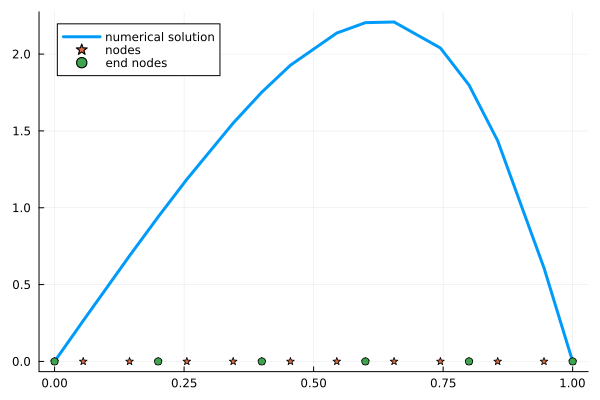

In [24]:
P = 4
Q = P
nelx = 5
IEN = GetConnectivity(P, nelx)
f(x) = (1-pi^2) * sin(x*pi)
kappa(x) = 0.6 .+ 0.4 * cos.(pi*x)
x, xn, u = GetFESolution(P, Q, kappa, f, "GAUSS", IEN; a=0, b=1)
plot(xn, u, label = "numerical solution", )
scatter!(xn, zero, marker=:star, label = "nodes")
scatter!(x, zero, marker=:circle, label = "end nodes", legend=:topleft)

# Computing Residual instead of solving u = A\ F
It is common in FE courses that we solve the problem like what we did in GetFESolution function. Another approach is to compute the residual (A*u - F) and solve it with NLSolve package as follow

In [25]:
function xnodal(x, P)
    num_elem = length(x) - 1
    xn = Float64[]
    x_ref, _ = gausslobatto(P)
    for e in 1:num_elem
        # Get coordinate of the end nodes of each element
        xL, xR = x[e:e+1]
        # Nodal coordinate of each element
        xe = (xL + xR)/2 .+ (xR - xL)/2 * x_ref[1+(e>1):end]
        # Store nodal coordinates
        append!(xn, xe)
    end
    xn
end

xnodal (generic function with 1 method)

In [26]:
struct FESpace
    a::Float64
    b::Float64
    P::Int
    Q::Int
    num_elem::Int
    x::Vector
    xn::Vector
    IEN::Matrix
    function FESpace(a, b, P, Q, num_elem)
        x = LinRange(a, b, num_elem+1)
        xn = xnodal(x, P)
        IEN = GetConnectivity(P, num_elem)
        
        new(a, b, P, Q, num_elem, x, xn, IEN)
    end
end

In [27]:
function fe_element(fe, e)
    # coordinate, quadrature, and basis on reference element [-1,1]
    x_ref, q_ref, w_ref, B, D = febasis(fe.P, fe.Q, "GAUSS")
    # Get coordinate of the end nodes of each element
    xL, xR = fe.x[e:e+1]
    # Update quadrature
    q = (xL + xR)/2 .+ (xR - xL)/2 * q_ref
    w = (xR - xL)/2 * w_ref
    # Jacobian
    dXdx = ones(fe.Q) * 2 / (xR - xL)
    # Element restriction
    E = GetElementRestriction(fe.IEN, e)
    E = sparse(E)
    q, w, E, dXdx, B, D
end

fe_element (generic function with 1 method)

In [28]:
# This function is exactly the same as GetFESolution but we return residual (A*u - F)
function ComputeResidual(u_in, fe, kappa, f)

    global_dof = maximum(fe.IEN)
    F = zeros(global_dof, 1)
    A = zeros(global_dof,global_dof)
    
    for e=1:fe.num_elem
        q, w, E, dXdx, B, D = fe_element(fe, e)
        # Local operators
        Ke = (D' .* dXdx) * diagm(w .* kappa.(q)) * (dXdx .* D)
        Me = B' * diagm(w) * B  # v^T * u
        Fe = B' * diagm(w) * f.(q)        
        Ae = Me - Ke
        # Assemble
        A = A + E' * Ae * E
        F = F + E' * Fe

    end
    
    # Dirichlet Boundary conditions
    F[[1,end]] .= 0
    A[1, :] .= 0
    A[1, 1] = 1
    A[end, :] .= 0
    A[end, end] = 1
    
   return A*u_in - F 
end

ComputeResidual (generic function with 1 method)

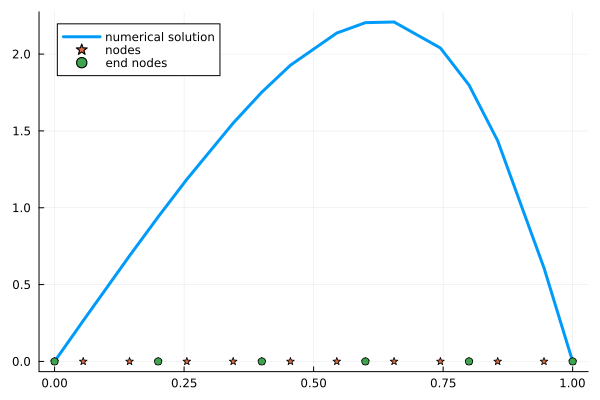

In [29]:
fe = FESpace(0, 1, 4, 4, 5)
u0 = zero(fe.xn)
f(x) = (1-pi^2) * sin(x*pi)
kappa(x) = 0.6 .+ 0.4 * cos.(pi*x)
sol = nlsolve(u -> ComputeResidual(u, fe, kappa, f), u0; method=:newton)
plot(fe.xn, sol.zero, label = "numerical solution", )
scatter!(fe.xn, zero, marker=:star, label = "nodes")
scatter!(fe.x, zero, marker=:circle, label = "end nodes", legend=:topleft)

# <font color='red'> MatrixFree approach
In matrix-free approach instead of assembling matrix A like what we did in ComputeResidual function and computed the residual, we compute residual for each element (ve vector below) and assemble the residual vector (v+=E' * ve)

# Finite element residual assembly
$$ v^T F(u) \sim \int_\Omega v\cdot f_0(u, \nabla u) + \nabla v\cdot f_1(u, \nabla u) = 0, \quad \forall v$$
$$ \sum_e \mathcal E_e^T \Big( B^T W \left\lvert \frac{\partial x}{\partial X} \right\rvert f_0(\tilde u, \nabla \tilde u) + D^T \left(\frac{\partial X}{\partial x}\right)^{T} W \left\lvert \frac{\partial x}{\partial X} \right\rvert f_1(\tilde u, \nabla\tilde u) \Big) = 0 $$
where $\tilde u = B \mathcal E_e u$ and $\nabla \tilde u = \frac{\partial X}{\partial x} D \mathcal E_e u$ are the values and gradients evaluated at quadrature points.

In [30]:
kappa(x) = 0.6 .+ 0.4*sin(pi*x/2)
fq(q, u, Du) = 0*u .- 1, kappa.(q) .* Du
dfq(q, u, du, Du, Ddu) = 0*du, kappa.(q) .* Ddu

function fe_residual(u_in, fe, fq; bci=[1], bcv=[1.])
    u = copy(u_in); v = zero(u)
    u[bci] = bcv
    
    for e in 1:fe.num_elem
        q, w, E, dXdx, B, D = fe_element(fe, e)
        ue = E * u
        uq = B * ue
        Duq = dXdx .* (D * ue)
        f0, f1 = fq(q, uq, Duq)
        ve = B' * (w .* f0) + D' * (dXdx .* w .* f1)
        v += E' * ve
    end
    v[bci] = u_in[bci] - u[bci]
    v
end

fe_residual (generic function with 1 method)

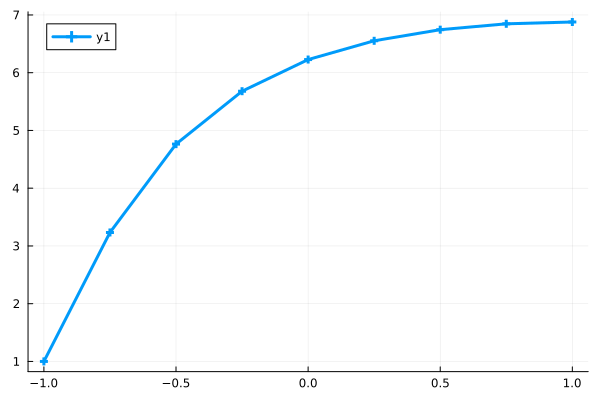

In [31]:
fe = FESpace(-1, 1, 3, 3, 4)
u0 = zero(fe.xn)
size(u0)
sol = nlsolve(u -> fe_residual(u, fe, fq), u0; method=:newton)
plot(fe.xn, sol.zero, marker=:auto)

# Finite element Jacobian assembly

$$ v^T F(u) \sim \int_\Omega v\cdot f_0(u, \nabla u) + \nabla v\cdot f_1(u, \nabla u) = 0, \quad \forall v$$
$$ v^T J(u) du \sim \int_\Omega v\cdot df_0(u, du, \nabla u, \nabla du) + \nabla v\cdot df_1(u, du, \nabla u, \nabla du) = 0, \quad \forall v$$

In [32]:
function fe_jacobian(u_in, fe, dfq; bci=[1], bcv=[1.])
    u = copy(u_in); u[bci] = bcv
    rows, cols, vals = Int[], Int[], Float64[]
    for e in 1:fe.num_elem
        q, w, E, dXdx, B, D = fe_element(fe, e)
        P = fe.P
        ue = E * u
        uq = B * ue; Duq = dXdx .* (D * ue)
        K = zeros(P, P)
        for j in 1:fe.P
            du = B[:,j]
            Ddu = dXdx .* D[:,j]
            df0, df1 = dfq(q, uq, du, Duq, Ddu)
            K[:,j] = B' * (w .* df0) + D' * (dXdx .* w .* df1)
        end
        inds = rowvals(sparse(E'))
        append!(rows, kron(ones(P), inds))
        append!(cols, kron(inds, ones(P)))
        append!(vals, vec(K))
    end
    A = sparse(rows, cols, vals)
    A[bci, :] .= 0; A[:, bci] .= 0
    A[bci,bci] = diagm(ones(length(bci)))
    A
end

fe_jacobian (generic function with 1 method)

In [33]:
sol = nlsolve(u -> fe_residual(u, fe, fq),
    u -> fe_jacobian(u, fe, dfq),
    u0;
    method=:newton)

Results of Nonlinear Solver Algorithm
 * Algorithm: Newton with line-search
 * Starting Point: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
 * Zero: [1.0, 3.2330668329347056, 4.763363332972804, 5.679478339657094, 6.227478131430274, 6.552900706733805, 6.744987353417804, 6.84638843314423, 6.878044892676182]
 * Inf-norm of residuals: 0.000000
 * Iterations: 1
 * Convergence: true
   * |x - x'| < 0.0e+00: false
   * |f(x)| < 1.0e-08: true
 * Function Calls (f): 2
 * Jacobian Calls (df/dx): 2

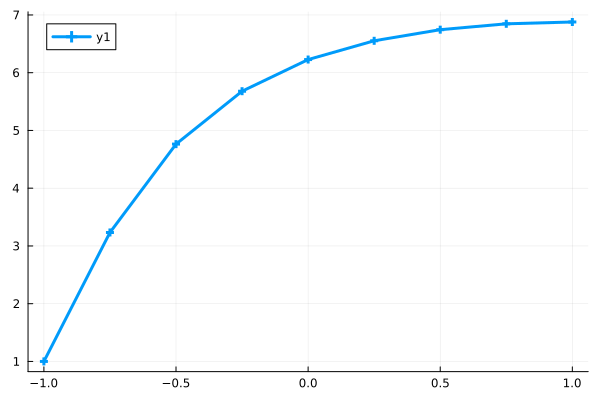

In [34]:
plot(fe.xn, sol.zero, marker=:auto)

# p-Multigrid

So far every linear solve has been a single dense factorization ($A \backslash \mathrm{rhs}$)
on one polynomial order $P$. **p-multigrid** instead solves the same problem on a
hierarchy of polynomial orders $P_f > P_c$ built on the *same* mesh: a cheap smoother
removes the high-frequency (oscillatory) part of the error on the fine space $\mathcal V_f$,
and a small, well-conditioned problem on the coarse space $\mathcal V_c$ removes the
low-frequency part. This is exactly the algorithm libCEED/Ratel use for `PCMG`
preconditioning of high-order operators (see `CeedBasisCreateProjection` and
`CeedOperatorMultigridLevelCreate` in `libCEED/interface/ceed-basis.c` and
`ceed-preconditioning.c`), except there the coarse operator is reassembled from the
physics, or built by projecting through quadrature with a pseudoinverse when the
quadrature spaces don't match exactly. Here, because our coarse nodal basis (order $P_c$)
is a subset of what the fine nodal basis (order $P_f$) can represent exactly (both use
GLL nodes, and GLL always includes the two endpoints $\pm 1$), the prolongation is just
**exact polynomial interpolation** -- no quadrature or pseudoinverse needed.

## Two nested spaces on one reference element

Let $\{\phi_j^c\}_{j=1}^{P_c}$ be the nodal (Lagrange) basis of degree $P_c - 1$ built from
the coarse GLL nodes $\{x_j^c\}$, and $\{\phi_i^f\}_{i=1}^{P_f}$ the same construction on the
fine GLL nodes $\{x_i^f\}$, with $P_f > P_c$. Because $\deg \phi_j^c = P_c - 1 \le P_f - 1$,
every coarse basis function is *exactly* representable in the fine space, so we can define
the **prolongation** (interpolation) operator $I_c^f \in \mathbb R^{P_f \times P_c}$ by

$$ (I_c^f)_{ij} = \phi_j^c(x_i^f), $$

i.e. row $i$ of $I_c^f$ is just the coarse basis functions evaluated at the fine node $x_i^f$.
This is precisely what `febasis(Pc, Pf, "GLL")` already computes: call it with the coarse
order as $P$ and the fine GLL nodes as the evaluation points $Q$, and the returned $B$ matrix
*is* $I_c^f$.

## Restriction and the coarse operator (RAP)

The **restriction** operator is taken to be the transpose (the standard *variational*, or
Galerkin, choice):

$$ I_f^c = (I_c^f)^T \in \mathbb R^{P_c \times P_f}. $$

Given the fine-level operator $A_f$ (assembled once, exactly as in `general_galerkin`),
the coarse operator is **not** reassembled from $\kappa$ and $f$ -- it is built purely
algebraically by the **Galerkin triple product**

$$ A_c = I_f^c \, A_f \, I_c^f = (I_c^f)^T A_f I_c^f, $$

which is the "RAP" (Restrict-times-A-times-Prolong) coarse-grid operator used by essentially
every multigrid method. It automatically inherits symmetry and positive-definiteness from
$A_f$ -- *provided* the Dirichlet rows of $A_f$ were eliminated **symmetrically** (zero the
column too, not just the row): if only the row is zeroed (as `general_galerkin` does above),
$A_f$ loses symmetry and $A_c$ picks up a spurious sign-indefinite boundary row, which makes
the two-grid iteration diverge. `general_galerkin_sym` below is identical to
`general_galerkin` except for this one fix.

## Two-grid V-cycle

$$
\begin{aligned}
&\textbf{1. Pre-smooth (Jacobi) on the fine level: } && u \leftarrow u + \omega D^{-1}(b - A_f u) \quad (\nu_1 \text{ sweeps})\\
&\textbf{2. Fine residual: } && r = b - A_f u \\
&\textbf{3. Restrict: } && r_c = I_f^c\, r \\
&\textbf{4. Assemble coarse operator: } && A_c = (I_c^f)^T A_f I_c^f \\
&\textbf{5. Coarse solve } (\text{stand-in for AMG; } A_c \text{ is small so we just use } \backslash): && e_c = A_c^{-1} r_c \\
&\textbf{6. Prolong \& correct: } && u \leftarrow u + I_c^f e_c \\
&\textbf{7. Post-smooth (Jacobi) on the fine level: } && u \leftarrow u + \omega D^{-1}(b - A_f u) \quad (\nu_2 \text{ sweeps})
\end{aligned}
$$

Repeating this V-cycle drives $u$ toward the fine-level solution $A_f u = b$ without ever
factorizing the (potentially ill-conditioned, high-order) fine matrix directly.

In [35]:
function ProlongationMatrix(Pc, Pf)
    """
    Coarse-to-fine prolongation I_c^f: the order-Pc nodal (Lagrange) basis
    evaluated at the Pf fine GLL nodes. Exact polynomial interpolation since
    the coarse space is nested inside the fine space (both built from GLL nodes,
    which always include the shared endpoints +/-1).

    3D: this 1D matrix is exactly what libCEED tensorizes. On a tensor-product
    (hex) element the 3D prolongation is the Kronecker product of this same
    1D matrix with itself along each axis, Icf_3d = Icf ⊗ Icf ⊗ Icf, so this
    construction generalizes unchanged.

    @ref libCEED's CeedBasisCreateProjection (interface/ceed-basis.c), which
    builds this same interp_to^+ * interp_from projection matrix; it is used
    inside CeedOperatorMultigridLevelCreate / CeedOperatorMultigridLevelCreateTensorH1
    (interface/ceed-preconditioning.c) as the shared basis of libCEED's
    prolongation and restriction CeedOperators (see jacobi_smooth and
    pmg_vcycle below for where those two operators come in).
    """
    _, _, _, Icf, _ = febasis(Pc, Pf, "GLL")
    Icf  # size Pf x Pc
end

ProlongationMatrix (generic function with 1 method)

### Aside: the general (non-nested) case -- libCEED's pseudoinverse projection

`ProlongationMatrix` above only works because the coarse GLL nodal basis is *exactly*
representable in the fine space (both are polynomial GLL bases sharing the endpoints
$\pm1$), so "evaluate the coarse basis at the fine nodes" is an exact answer, not an
approximation. That trick breaks down whenever the two bases are **not nested** this way --
e.g. projecting between different element types (simplex vs. tensor-product), different
node families, modal/hierarchical bases, or an hp-adaptive level pair where the coarse space
isn't literally a subspace of the fine one. libCEED has to handle all of those cases too, so
`CeedBasisCreateProjection` doesn't use our node-evaluation trick -- it uses a general
least-squares fit through a *shared quadrature space* instead. Worth knowing for later, even
though our GLL case never needs it.

**The general recipe** (@ref `CeedBasisCreateProjectionMatrices`,
`interface/ceed-basis.c:231`, and the public entry point `CeedBasisCreateProjection`,
`interface/ceed-basis.c:1879`):

1. Pick $Q$ evaluation/quadrature points that both bases share (libCEED requires this --
   it's the `Q_to == Q_from` check at the top of `CeedBasisCreateProjectionMatrices`).
2. Evaluate each basis there: $I_{\text{from}} \in \mathbb R^{Q\times P_{\text{from}}}$,
   $I_{\text{to}} \in \mathbb R^{Q\times P_{\text{to}}}$.
3. Compute $I_{\text{to}}^{+}$, the Moore-Penrose pseudoinverse of $I_{\text{to}}$ (via SVD
   -- @ref `CeedMatrixPseudoinverse`, `interface/ceed-basis.c:1273`).
4. The projection (prolongation) matrix is
   $$ P_{\text{proj}} = I_{\text{to}}^{+}\, I_{\text{from}} \ \in \mathbb R^{P_{\text{to}} \times P_{\text{from}}}. $$

**Why this is the right formula.** Given nodal coefficients $c_{\text{from}}$, the vector
$y = I_{\text{from}}\, c_{\text{from}}$ is the from-basis's values at the $Q$ points.
$I_{\text{to}}^{+}$ then returns the $c_{\text{to}}$ that minimizes
$\lVert I_{\text{to}}\, c_{\text{to}} - y \rVert_2$ -- the to-basis's nodal coefficients whose
values at those same $Q$ points best match $y$, in the plain (unweighted) least-squares
sense. Note this is *not* a quadrature-weighted $L^2$ projection (no $\mathrm{diag}(w)$
appears anywhere) -- it is an algebraic best fit at the quadrature points only, which is
enough to be exact whenever an exact answer exists.

**How it collapses to our simple case.** If $Q$ is chosen to be the fine basis's own nodes,
then $I_{\text{to}}$ is that basis evaluated at its own nodes, i.e. $I_{\text{to}} = I$
(the identity), so $I_{\text{to}}^{+} = I$ and $P_{\text{proj}} = I_{\text{from}}$ -- exactly
"evaluate the coarse basis at the fine nodes," our `ProlongationMatrix`. So our formula is
the special case of this one for nested, node-matching bases; the pseudoinverse version is
the fallback for everything else.

**Applying it in practice**, once you have $P_{\text{proj}}$: everything downstream is
unchanged from what we already built -- restriction is $P_{\text{proj}}^T$, the coarse
operator is the Galerkin triple product $A_c = P_{\text{proj}}^T A_f P_{\text{proj}}$, and
(if assembling over multiple elements) the same multiplicity correction from
`BenchMark2D.ipynb` applies for shared dofs.

In [36]:
function jacobi_smooth(A, b, u, niter; omega=2/3)
    """
    niter sweeps of weighted (damped) Jacobi: u <- u + omega * D^{-1} (b - A*u)

    3D: unchanged -- D is just the operator's diagonal, regardless of
    dimension or element topology.

    @ref PETSc's PCJACOBI (src/ksp/pc/impls/jacobi/jacobi.c). Ratel wraps this
    exact point-Jacobi preconditioner in KSPCHEBYSHEV as its p-multigrid
    smoother (ratel/src/internal/ratel-pmg.c); we use plain undamped/
    unaccelerated Jacobi here to keep the teaching example simple.
    """
    dinv = 1 ./ diag(A)
    for _ in 1:niter
        r = b - A*u
        u = u + omega * (dinv .* r)
    end
    u
end

jacobi_smooth (generic function with 1 method)

In [37]:
function general_galerkin_sym(P, Q, kappa, f, Qmode; xL=0, xR=1)
    """
    Same as general_galerkin (mass - stiffness on [xL,xR]), but the Dirichlet
    rows are eliminated symmetrically (row AND column) so that the Galerkin
    coarse operator Ac = Icf' * A * Icf stays consistent (symmetric, and with
    the correct sign) with the fine operator A.

    3D: the same symmetric elimination is applied per boundary dof, however
    many a 3D mesh's boundary has -- nothing here is dimension-specific.

    @ref PETSc's MatZeroRowsColumns (src/mat/interface/matrix.c), which does
    exactly this row+column elimination (and is what you'd call instead of
    hand-rolling A[1,:].=0; A[:,1].=0 on a real assembled PETSc Mat).
    """
    x, q, w, B, D = febasis(P, Q, Qmode)

    x = (xL + xR)/2 .+ (xR - xL)/2*x
    q = (xL + xR)/2 .+ (xR - xL)/2*q
    w = (xR - xL)/2 * w
    dXdx = ones(Q) * 2 / (xR - xL)
    K = (D' .* dXdx) * diagm(w .* kappa.(q)) * (dXdx .* D)
    M = B' * diagm(w) * B  # v^T * u
    rhs = B' * diagm(w) * f.(q)

    A = M - K
    # Dirichlet Boundary conditions (symmetric elimination)
    rhs[[1,end]] .= 0
    A[1, :] .= 0; A[:, 1] .= 0; A[1, 1] = 1
    A[end, :] .= 0; A[:, end] .= 0; A[end, end] = 1
    A, rhs, x
end

general_galerkin_sym (generic function with 1 method)

In [38]:
function pmg_vcycle(A, b, u, Icf; nu1=2, nu2=2, omega=2/3)
    """
    Two-grid V-cycle: pre-smooth -> restrict -> RAP coarse solve -> prolong -> post-smooth.

    3D: unchanged -- everything below is plain linear algebra on already-
    assembled matrices/vectors, so the same code runs whatever the spatial
    dimension is; only Icf's own construction needs the tensor-product
    generalization noted in ProlongationMatrix.

    @ref PETSc's PCMG (src/ksp/pc/impls/mg/mg.c, PCApply_MG) implements this
    same V-cycle in general. The RAP coarse-operator step (Ac = Icf'*A*Icf)
    corresponds to PCMGSetGalerkin(pc, PC_MG_GALERKIN_BOTH). Ratel's actual
    p-multigrid (ratel/src/internal/ratel-pmg.c) instead re-discretizes the
    coarse operator directly from the physics at the coarse order -- cheaper
    and more accurate for its nonlinear operators -- so RAP (what we do here)
    should be read as the general-purpose algebraic fallback, not what Ratel
    itself does.
    """
    Ifc = Icf'  # restriction = transpose of prolongation (variational/Galerkin choice)

    # 1. pre-smooth on the fine level
    u = jacobi_smooth(A, b, u, nu1; omega=omega)

    # 2-3. fine residual, then restrict to the coarse level
    r = b - A*u
    rc = Ifc * r

    # 4. coarse operator via the Galerkin triple product (RAP) -- no reassembly needed
    Ac = Ifc * A * Icf

    # 5. coarse solve (stand-in for AMG; Ac is small so a direct solve is fine)
    ec = Ac \ rc

    # 6. prolong the correction back to the fine level
    u = u + Icf * ec

    # 7. post-smooth on the fine level
    u = jacobi_smooth(A, b, u, nu2; omega=omega)
    u
end

pmg_vcycle (generic function with 1 method)

### Two-grid demo: $P_f = 20 \to P_c = 5$

We build the fine-level operator once (order $P_f=20$, same physics as `general_galerkin`),
get a reference solution by direct factorization, then throw it away and recover it purely
through V-cycles: Jacobi smoother $\to$ restrict $\to$ assemble coarse matrix $\to$ prolong
$\to$ Jacobi smoother.

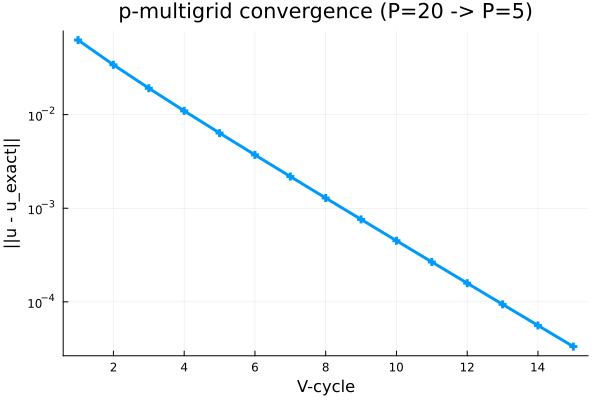

In [39]:
Pf, Pc = 20, 5
kappa(x) = 0.6 .+ 0.4 * cos.(pi*x)
f(x) = (1-pi^2) * sin(x*pi)

A, rhs, x = general_galerkin_sym(Pf, Pf, kappa, f, "GAUSS")
u_exact = A \ rhs  # reference solve, for checking convergence only

Icf = ProlongationMatrix(Pc, Pf)

u = zeros(Pf)
err = Float64[]
for it in 1:15
    global u = pmg_vcycle(A, rhs, u, Icf; nu1=2, nu2=2, omega=2/3)
    push!(err, norm(u - u_exact))
end
plot(err, marker=:auto, yscale=:log10, xlabel="V-cycle", ylabel="||u - u_exact||",
    title="p-multigrid convergence (P=$Pf -> P=$Pc)", legend=false)

### Aside: is this "iterate the V-cycle to convergence" what Ratel actually does?

Not quite -- there are two different ways to use a V-cycle, and the loop above uses the
simpler one for teaching purposes:

1. **Multigrid as a stand-alone solver** (what we did above): repeatedly apply
   `pmg_vcycle` as a fixed-point iteration, $u_{k+1} = \text{Vcycle}(u_k)$, until it
   converges. This is exactly analogous to a stationary iterative method (Jacobi/Gauss-Seidel
   iterated to convergence) -- simple to reason about, and it does converge here, but it's
   not the most robust option in general.
2. **Multigrid as a preconditioner for an outer Krylov method** (CG or GMRES): the V-cycle
   is applied *once* per outer Krylov iteration, just to precondition the residual; it's the
   Krylov method's own optimality (minimizing the residual over a growing subspace) that
   actually drives convergence, not repetition of the V-cycle itself.

**Ratel does (2), not (1).** Concretely (@ref `ratel/src/internal/ratel-pmg.c` and
`ratel/src/ratel-solver.c`):

- Ratel's p-multigrid is wrapped in a custom PETSc `PC` type called `PCpMG`
  (`RatelPCPMGCreate`, `ratel-pmg.c:981`). Its `RatelPCPMGSetUp_Internal` builds a genuine
  `PCMG` object with the Chebyshev/Jacobi smoothers we already discussed
  (`PCMGSetNumberSmooth(pc_mg, 3)`, `ratel-pmg.c:591`) and `PCMGSetCycleType(pc_mg,
  PC_MG_CYCLE_V)` (`ratel-pmg.c:592`) -- so far, the same V-cycle as ours.
- `RatelPCApply_PMG` (`ratel-pmg.c:872`) applies that `PCMG` **exactly once**
  (`PCApply(pmg->pc_mg, X_in, X_out)`) -- there is no internal "loop until converged" here at
  all.
- `RatelKSPSetup` (`ratel-solver.c:579-636`) sets this `PCpMG` as the preconditioner of an
  *outer* Krylov solver -- `KSPCG` for SPD single-field problems, `KSPGMRES` otherwise -- and
  it is that outer `KSPSolve` loop that iterates to convergence, calling the V-cycle once per
  Krylov iteration as a preconditioner application, not as the convergence loop itself.
- This matches general PETSc practice, confirmed in `petsc/src/ksp/pc/impls/mg/mg.c`:
  `PCApply_MG_Internal` runs `mg->cyclesperpcapply` V-cycles per `PCApply` call, and that
  defaults to exactly 1 (`PCCreate_MG`) unless you explicitly call
  `PCMGMultiplicativeSetCycles`. Ratel never does, so every `PCApply` there really is one
  V-cycle, feeding an outer Krylov method.

**Why bother with the outer Krylov wrapper at all?** MG-preconditioned CG/GMRES is generally
faster and more robust than bare V-cycle iteration, especially when the smoother isn't a
perfect match for the operator's spectrum (exactly the situation Chebyshev-Jacobi is trying
to improve, but even Chebyshev-Jacobi is imperfect) -- the Krylov method's subspace
minimization mops up whatever the V-cycle didn't fully damp. We iterated the bare V-cycle
here only because it's simpler to see the multigrid mechanics in isolation, without an outer
CG/GMRES loop obscuring which part is doing what.

In our step-by-step notation, what Ratel actually runs is one level more nested: the outer
loop is a Krylov iteration on $A_f u = b$, and steps 1-7 above become a single
**preconditioner application** $z_k = M_{\text{MG}}^{-1} r_k$ computed by one V-cycle (with
Chebyshev-Jacobi in place of plain weighted Jacobi), not the thing being iterated to
convergence itself:

$$
\begin{aligned}
&\textbf{0. Outer Krylov iteration (CG or GMRES) on } A_f u = b: && r_k = b - A_f u_k \\[4pt]
&\textbf{1. Precondition -- one V-cycle solving } A_f z \approx r_k,\ \text{started from } z^{(0)}=0: \\
&\qquad \textbf{1a. Pre-smooth (Chebyshev-Jacobi):} && z \leftarrow \text{Cheb-Jacobi sweeps on } A_f z = r_k,\ z^{(0)}=0 \\
&\qquad \textbf{1b. Restrict the } \textit{current} \textbf{ fine residual:} && r_c = I_f^c\,\big(r_k - A_f z\big) \\
&\qquad \textbf{1c. Coarse solve for a } \textit{correction} \textbf{, not a solution} \\
&\qquad \phantom{\textbf{1c.}} (\text{coarse initial guess is } 0\text{, so this solves} \\
&\qquad \phantom{\textbf{1c.}} \text{the defect equation } A_c e_c \approx r_c\text{, not a BVP}): && e_c = A_c^{-1} r_c \\
&\qquad \textbf{1d. Prolong \& correct:} && z \leftarrow z + I_c^f e_c \\
&\qquad \textbf{1e. Post-smooth (Chebyshev-Jacobi):} && z \leftarrow \text{further Cheb-Jacobi sweeps on } A_f z = r_k \\
&\qquad \phantom{\textbf{1e.}} z_k := z \quad \approx\ e_f := u - u_k \quad \text{(the true fine-grid error)} \\[4pt]
&\textbf{2. Krylov update (preconditioned CG shown explicitly):} \\
&\qquad \textbf{2a. Search direction:} && p_k = z_k + \frac{z_k^T r_k}{z_{k-1}^T r_{k-1}}\, p_{k-1} \qquad (p_0 = z_0) \\
&\qquad \textbf{2b. Step length:} && \alpha_k = \frac{z_k^T r_k}{p_k^T A_f p_k} \\
&\qquad \textbf{2c. Update solution \& residual:} && u_{k+1} = u_k + \alpha_k p_k, \qquad r_{k+1} = r_k - \alpha_k A_f p_k \\[4pt]
&\textbf{3. Repeat steps 0-2 until } \lVert r_k \rVert \text{ is small.}
\end{aligned}
$$

Every arrow above is a real line of code, not an approximation of one -- checked directly
against `PCMGMCycle_Private` (`petsc/src/ksp/pc/impls/mg/mg.c:14-98`) for steps 1a-1e, and
`KSPSolve_CG` (`petsc/src/ksp/ksp/impls/cg/cg.c:119-334`) for step 2:

- **$z^{(0)}=0$ (step 1):** `PCApply_MG_Internal` zeroes the solution vector before running
  any cycles (`mg.c:626`, `VecZeroEntries(x)`) -- the whole V-cycle computes an approximate
  solution to $A_f z \approx r_k$ *from scratch*, which is exactly what a preconditioner
  application is supposed to produce.
- **1a/1e (smooth):** `KSPSolve(mglevels->smoothd, mglevels->b, mglevels->x)` (`mg.c:27`,
  pre) and the same with `smoothu` (`mg.c:98`, post) -- `mglevels->b` *is* $r_k$ on the
  finest level (`PCApply_MG_Internal` sets `mglevels[levels-1]->b = b`, the PC's input).
- **1b (restrict):** the fine residual is recomputed after smoothing via `MatResidual`
  (`PCMGResidualDefault`, `mgfunc.c:20-22`, i.e. $r_k - A_f z$, not $r_k$ itself), then
  `MatRestrict(mglevels->restrct, mglevels->r, mgc->b)` (`mg.c:69`) -- so the coarse level's
  "RHS" field literally *is* this restricted residual, reusing the same `b` field name that
  held the true RHS on the finest level only.
- **1c (why a correction, not a solution):** `VecZeroEntries(mgc->x)` (`mg.c:81`) zeros the
  coarse initial guess right before the coarse solve -- solving $A_c x \approx (\text{RHS})$
  from $x=0$ against a residual RHS is, by definition, solving for the *error* $e_c$, not for
  an independent coarse-grid solution.
- **1d (prolong \& correct):** `MatInterpolateAdd(mglevels->interpolate, mgc->x,
  mglevels->x, mglevels->x)` (`mg.c:86-87`) computes exactly $z \leftarrow I_c^f e_c + z$
  (`MatInterpolateAdd(A,x,y,w)` computes $w = Ax+y$, `matrix.c:8802`) -- $e_c$ is *added onto*
  the existing $z$, never used on its own.
- **2a/2b/2c (CG):** `KSP_PCApply(ksp, R, Z)` (`cg.c:170,332`) is the $z_k =
  \text{PCApply}(r_k)$ step; `beta = z'r` (`cg.c:215,334`) then `p <- z + b*p` (`cg.c:244,249`)
  is 2a; `a = beta/p'w` with `w=Ap` (`cg.c:257-288`) is 2b; `x <- x+ap`, `r <- r-aw`
  (`cg.c:302-303`) is 2c. Note $z_k$ replaces $r_k$ only in building the direction/step
  length -- the residual update itself always uses the true $r_k$, not $z_k$.
- **Important: the update is $u_{k+1}=u_k+\alpha_k p_k$, *not* $u_{k+1}=u_k+z_k$.** Only on
  the very first CG iteration does $p_0=z_0$ exactly (`VecCopy(Z, P)`, `cg.c:235`, no earlier
  direction to combine with) -- from then on $z_k$ is first conjugated with the *previous*
  direction, `VecAYPX(P, b, Z)` i.e. $p_k \leftarrow z_k + \beta_k p_{k-1}$ (`cg.c:249`),
  and only that combined $p_k$, scaled by the separately computed optimal step length
  $\alpha_k$ (`VecAXPY(X, a, P)`, `cg.c:302`), is what actually moves $u_k$. So even though
  $z_k \approx e_f$ is an estimate of the full error, CG never just adds it back at face
  value -- it only ever uses $z_k$ as an ingredient for picking the best combination of
  *all* past search directions. (Our own bare `pmg_vcycle` loop, with no outer CG, *does* do
  the naive `u = u + Icf*ec` -- that contrast is exactly what makes MG-as-preconditioner
  different from MG-as-solver.)

And confirmed there's no special-casing anywhere in between: `RatelPCApply_PMG`
(`ratel-pmg.c:872`) is a one-line pass-through, `PCApply(pmg->pc_mg, X_in, X_out)`, and
`PCpMG` is registered as an ordinary `PC` type (`PCRegister(RATEL_PCPMG, ...)`,
`ratel-pmg.c:981`) -- `KSPSolve_CG`/`KSPSolve_GMRES` call the fully generic `KSP_PCApply` →
`PCApply` dispatch (`kspimpl.h:412-423`, `precon.c:525-529`) with no idea a multigrid
V-cycle is what's actually running underneath.

Step 1 here is exactly our `pmg_vcycle`/`pmg_vcycle_cheb` (one pass, not iterated on its
own) -- it is step 2, the Krylov update, that is actually iterated to convergence, with the
V-cycle re-invoked fresh as a preconditioner on each new residual $r_k$.

**Aside: why prolong $e_c$ and not the leftover coarse residual $r_c - A_c e_c$?**
Because our coarse solve is exact (`Ac \ rc`), that leftover is zero to machine precision
(checked numerically: $\lVert r_c-A_ce_c\rVert/\lVert r_c\rVert \sim 10^{-16}$ on our own
$P_f=20\to P_c=5$ operator) -- there'd be nothing to prolong. But even when a coarse solve
*isn't* exact (Ratel's real one literally isn't: `ratel-pmg.c:582-586` sets the coarse KSP
to `KSPPREONLY` with `PCGAMG`, i.e. one GAMG application, not a guaranteed-exact direct
solve), the code still never prolongs a residual -- `MatInterpolateAdd` (`mg.c:87`) always
prolongs `mgc->x` (the correction $e_c$ itself), never a residual. The reason is more than
convention: a residual and a correction are different *kinds* of object (residuals move
between levels via restriction, corrections via prolongation) -- a residual only becomes
something you can validly add onto $z$ *after* an operator solve converts it into one,
which is precisely what the coarse solve does. If a coarse solve is inexact, standard
multigrid's fix is never "prolong the leftover and resolve" at that same level -- it's to
add another, coarser level, whose own restrict/correct machinery (the same 1a-1e pattern,
recursively -- see `PCMGMCycle_Private` calling itself at `mg.c:83`) absorbs whatever
residual remains; and any small leftover imperfection is exactly what post-smooth (1e) is
there to clean up, far more cheaply than re-solving for $z$ on the fine grid ever could.

**Aside: which of this shows up in `-log_view`?** There is no event called "KSPApply" --
`KSP_PCApply` (`kspimpl.h:412`) is a plain inline wrapper with no logging of its own, it just
calls `PCApply` directly, so that's the name that actually appears. Checked against the
exact registered event-name strings in `dlregisksp.c`:

| `-log_view` event | What it times | Maps to |
|---|---|---|
| `KSPSolve` | the *entire* outer Krylov solve | our whole loop: step 0 + step 2, repeated |
| `PCApply` | *one* preconditioner application | our whole step 1 (1a-1e) -- one V-cycle |
| `PCSetUp` | building the preconditioner (smoothers, $A_c$, $I_c^f$, ...) | one-time setup outside the loop |
| `KSPSetUp` | one-time KSP-level setup | before the loop starts |

Passing `-pc_mg_log` registers extra per-level events *inside* that one `PCApply`
(`mg.c:729-738`), breaking step 1 down further:

| Event | Maps to |
|---|---|
| `MGSmooth Level i` | steps 1a/1e (pre-/post-smooth) at level $i$ |
| `MGResid Level i` | the residual part of step 1b ($r_k - A_f z$) at level $i$ |
| `MGInterp Level i` | the restrict/prolong parts of steps 1b/1d at level $i$ |
| `MGSetup Level i` | one-time setup of that level's smoother |

Underneath all of this, raw linear-algebra events (`MatMult`, `MatMultAdd`, `VecMDot`,
`VecAXPY`, ...) fire on their own too, any time any part of the algorithm -- smoother, CG,
coarse solve -- does a matvec or vector op; they aren't multigrid-specific.

### Aside: a short review of CG, MINRES, and GMRES

Step 2 above just said "CG/GMRES step" -- here's what that actually means, all three built
from the same residual $r_k = b - A_f u_k$ (unpreconditioned, for clarity; with a
preconditioner $M$ you'd use $z_k = M^{-1}r_k$ in its place). All three pick the *next*
iterate from the same growing **Krylov subspace**
$\mathcal K_k = \mathrm{span}\{r_0,\ A_f r_0,\ A_f^2 r_0,\ \dots,\ A_f^{k-1} r_0\}$; they
differ in what they minimize over it and how expensive that is to do, and each requires a
different amount of structure in $A_f$.

**CG (Conjugate Gradient)** -- requires $A_f$ **SPD**. Minimizes the energy norm of the
error, $\lVert u - u_\star \rVert_{A_f} = \sqrt{(u-u_\star)^TA_f(u-u_\star)}$, over
$u_0+\mathcal K_k$. Because $A_f$ is symmetric, the Krylov basis can be built with a cheap
**3-term recurrence** (a symmetric Lanczos process) instead of storing every previous
direction:

$$
\begin{aligned}
\alpha_k &= \frac{r_k^T r_k}{p_k^T A_f p_k}, &
u_{k+1} &= u_k + \alpha_k p_k, &
r_{k+1} &= r_k - \alpha_k A_f p_k, \\
\beta_k &= \frac{r_{k+1}^T r_{k+1}}{r_k^T r_k}, &
p_{k+1} &= r_{k+1} + \beta_k p_k. & &
\end{aligned}
$$

Constant work and storage per iteration -- this is why CG is the default whenever $A_f$ is
SPD (exactly Ratel's choice, `KSPCG`, for single-field problems).

**MINRES** -- requires $A_f$ **symmetric**, but *allows indefinite* (some negative
eigenvalues), which breaks CG (the "energy norm" $\lVert\cdot\rVert_{A_f}$ isn't even a
valid norm if $A_f$ has mixed-sign eigenvalues). MINRES keeps the same cheap 3-term Lanczos
recurrence as CG (still cheap, since $A_f$ is still symmetric), but minimizes the plain
residual norm $\lVert b - A_f u_k \rVert_2$ over $u_0+\mathcal K_k$ instead of an energy
norm. This is the natural choice for symmetric saddle-point systems (e.g. the mixed
formulation in `MixedElasticity2D.ipynb`, where the pressure block makes the assembled
operator indefinite) -- cheap like CG, but robust to indefiniteness.

**GMRES** -- requires nothing beyond $A_f$ being invertible (works for **general,
non-symmetric** operators). Also minimizes $\lVert b - A_f u_k\rVert_2$ over
$u_0+\mathcal K_k$, but without symmetry there is no short recurrence: building an
orthogonal Krylov basis needs the full **Arnoldi process** (each new direction
orthogonalized against *every* previous one), so both cost and storage grow with $k$. In
practice this means periodically restarting (`GMRES(m)`, discarding the basis and starting
over every $m$ iterations) to keep it affordable -- the price paid for not requiring
symmetry. This is Ratel's fallback (`KSPGMRES`) whenever the assembled operator isn't SPD.

| | requires $A_f$ | minimizes | recurrence |
|---|---|---|---|
| **CG** | SPD | $\lVert u-u_\star\rVert_{A_f}$ | short (3-term, Lanczos) |
| **MINRES** | symmetric (indefinite OK) | $\lVert b-A_fu\rVert_2$ | short (3-term, Lanczos) |
| **GMRES** | general | $\lVert b-A_fu\rVert_2$ | grows (Arnoldi), usually restarted |

### Where does Gram-Schmidt come in?

It's the actual orthogonalization step *inside* Arnoldi (and, in disguise, inside Lanczos)
that builds the orthonormal Krylov basis $\{q_1,\dots,q_k\}$ all three methods minimize
over.

**Arnoldi (used by GMRES):**

$$
\begin{aligned}
&q_1 = r_0/\lVert r_0\rVert\\
&\text{for } j=1,\dots,k:\\
&\qquad w = A_f q_j\\
&\qquad \text{for } i=1,\dots,j: \quad h_{ij} = q_i^T w, \quad w \leftarrow w - h_{ij}\,q_i
   \qquad \leftarrow \textbf{this inner loop is Gram-Schmidt}\\
&\qquad h_{j+1,j} = \lVert w\rVert, \qquad q_{j+1} = w/h_{j+1,j}
\end{aligned}
$$

That inner loop -- "subtract off the projection onto every previous basis vector" -- is
exactly classical Gram-Schmidt. The $h_{ij}$'s collected over all $j$ form an upper
Hessenberg matrix $H_k$, and GMRES solves a small least-squares problem $\min_y \lVert
\lVert r_0\rVert e_1 - H_k y\rVert_2$ (via Givens rotations) to get $u_k = u_0 + Q_k y$.

This is precisely why GMRES's cost grows with $k$: orthogonalizing $w$ against $j$ previous
vectors is $O(jn)$ work, so it's $O(k^2n)$ total by step $k$ -- the "full Arnoldi, no short
recurrence" mentioned above *is* this Gram-Schmidt loop running against an ever-growing
list, and restarting (`GMRES(m)`) exists precisely to cap how long that list gets.

**Where Lanczos (CG/MINRES) escapes this**: it's the *same* Gram-Schmidt idea, but because
$A_f$ is symmetric, one can show $h_{ij}=0$ automatically for all $i<j-1$ -- the new vector
is already orthogonal to everything except the last one or two basis vectors, so the
Gram-Schmidt loop needs only 1-2 terms instead of $j$. That collapse is exactly the "3-term
recurrence" from CG/MINRES above -- not a different algorithm, just Gram-Schmidt
degenerating to almost nothing because of symmetry.

One practical caveat: naive ("classical") Gram-Schmidt as written above is numerically
unstable for larger $k$ (orthogonality degrades from roundoff); real GMRES implementations
use **modified Gram-Schmidt** (subtract each projection immediately using the
already-updated $w$, rather than all projections from the original $w$) or **Householder
reflections**, both more stable.

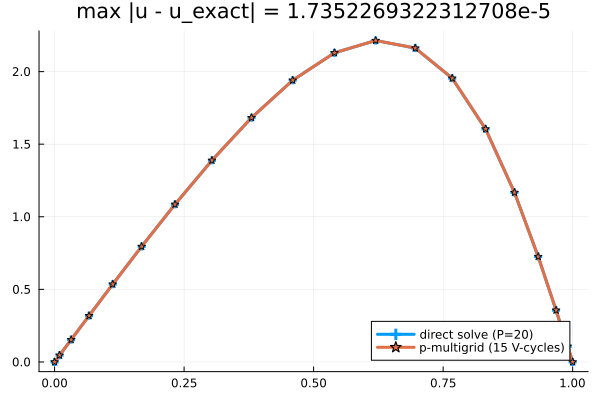

In [40]:
plot(x, u_exact, label="direct solve (P=$Pf)", marker=:auto)
plot!(x, u, label="p-multigrid ($(length(err)) V-cycles)", marker=:star, legend=:bottomright,
    title="max |u - u_exact| = $(maximum(abs.(u - u_exact)))")

## Chebyshev-accelerated Jacobi smoothing

`jacobi_smooth` above used a fixed $\omega = 2/3$. That value is the classic textbook choice
for the 1D Poisson stencil (where $D^{-1}A$ has eigenvalues spread over $(0,2)$), but it is
just one number tuned for one spectrum -- for a spectral-element operator the eigenvalues of
$D^{-1}A$ spread out as $P$ grows, and a fixed $\omega$ stops being a good smoother (try
bumping $P_f$ up in the demo above and watch the plain-Jacobi V-cycle degrade).

Real multigrid codes solve this with **Chebyshev-accelerated smoothing** instead of a fixed
$\omega$: given an estimate of the spectral interval $[\lambda_{\min}, \lambda_{\max}]$ of
$D^{-1}A$, Chebyshev semi-iteration is *the* polynomial of a given degree that minimizes the
worst-case error over that interval -- no hand-tuned relaxation parameter needed. And as a
*smoother* (as opposed to a general-purpose solver) it only needs to damp the **upper** part
of the spectrum, since the coarse grid is responsible for the rest; so the interval used is
deliberately biased away from zero.

**Step 1 -- estimate $\lambda_{\max}$.** A full eigendecomposition is far too expensive, so
we estimate it cheaply with a few steps of power iteration on $D^{-1}A$ (just matvecs).

**Step 2 -- target the upper spectrum.** We use $[\lambda_{\min}, \lambda_{\max}] =
[0.1,\ 1.1] \times \hat\lambda_{\max}$, exactly PETSc's default Chebyshev-smoother transform
(`chebyshevP->tform = (0, 0.1, 0, 1.1)` in `src/ksp/ksp/impls/cheby/cheby.c`).

**Step 3 -- Chebyshev semi-iteration.** With $\theta = (\lambda_{\max}+\lambda_{\min})/2$,
$\delta = (\lambda_{\max}-\lambda_{\min})/2$, $\sigma = \theta/\delta$, the standard 3-term
recurrence (Saad, *Iterative Methods for Sparse Linear Systems*, Chebyshev acceleration) is

$$
d_0 = \frac{D^{-1}r_0}{\theta}, \qquad
\rho_0 = \frac1\sigma, \qquad
u_1 = u_0 + d_0,
$$
$$
\rho_k = \frac{1}{2\sigma - \rho_{k-1}}, \qquad
d_k = \rho_k\rho_{k-1}\, d_{k-1} + \frac{2\rho_k}{\delta}\, D^{-1}r_k, \qquad
u_{k+1} = u_k + d_k.
$$

@ref PETSc's `KSPCHEBYSHEV` (`src/ksp/ksp/impls/cheby/cheby.c`, `KSPSolve_Chebyshev`)
implements exactly this recurrence; `KSPChebyshevEstEigSet` does the automatic eigenvalue
estimation (via a few CG/GMRES iterations rather than our simple power iteration). This is
what Ratel actually wraps `PCJACOBI` in for its p-multigrid smoother
(`ratel/src/internal/ratel-pmg.c`) -- so `pmg_vcycle_cheb` below is closer to Ratel's real
smoother than the fixed-$\omega$ `pmg_vcycle` was.

In [41]:
function estimate_lambda_max(A; niter=20)
    """
    Power-iteration estimate of the largest eigenvalue of D^{-1}A (a handful
    of matvecs -- no eigendecomposition needed).

    @ref PETSc's KSPChebyshevEstEigSet (src/ksp/ksp/impls/cheby/cheby.c) does
    the analogous automatic estimate, using a few iterations of an inner
    Krylov method (CG for SPD systems) instead of plain power iteration.
    """
    dinv = 1 ./ diag(A)
    x = randn(size(A,1))
    x /= norm(x)
    lambda = 0.0
    for _ in 1:niter
        x = dinv .* (A*x)
        lambda = norm(x)
        x /= lambda
    end
    lambda
end

estimate_lambda_max (generic function with 1 method)

### Aside: why does that loop actually converge to $\lambda_{\max}$?

This is the classical **power method** (@ref Golub & Van Loan, *Matrix Computations*,
4th ed., §8.2 "The Power Method"; Trefethen & Bau, *Numerical Linear Algebra*, Lecture 27).

Let $M = D^{-1}A$ have eigenpairs $(\lambda_i, v_i)$ with $|\lambda_1| \ge |\lambda_2| \ge
\dots$, and write a generic starting vector as $x_0 = \sum_i c_i v_i$ (a random $x_0$ has
$c_1 \ne 0$ with probability 1). After $k$ applications of $M$,

$$ M^k x_0 = \sum_i c_i \lambda_i^k v_i
   = \lambda_1^k \Big( c_1 v_1 + \sum_{i>1} c_i \Big(\frac{\lambda_i}{\lambda_1}\Big)^k v_i \Big). $$

Since $|\lambda_i/\lambda_1| < 1$ for $i>1$, the sum in parentheses vanishes as $k\to\infty$,
so the (renormalized) iterate converges to $v_1$ and the **growth factor per step**,
$\|Mx_k\|/\|x_k\|$, converges to $|\lambda_1|$ at the geometric rate $|\lambda_2/\lambda_1|$.
That growth factor is exactly what the loop tracks: each pass sets
`lambda = norm(x)` on a unit-norm `x` (so `lambda` *is* $\|Mx_k\|$), then renormalizes.

Checked directly against a full eigendecomposition on our own $P_f=20$ operator:

```
true max |eig(D^-1 A)|      = 2.8090787760577536
niter=1   estimate = 1.227     niter=10  estimate = 2.772
niter=3   estimate = 2.301     niter=20  estimate = 2.811
niter=5   estimate = 2.535     niter=40  estimate = 2.810
```

Converged to 3-4 significant digits by `niter=20`, which is all we need -- the Chebyshev
interval only has to be a reasonable ballpark, not an exact eigenvalue.

One subtlety worth flagging: "largest in magnitude" (what power iteration actually finds)
only equals "algebraically largest" ($\lambda_{\max}$) when every eigenvalue is real and
positive. That holds here because $D^{-1}A$ is similar to the SPD matrix $D^{-1/2}A
D^{-1/2}$ -- which is exactly why we needed the *symmetric* Dirichlet elimination in
`general_galerkin_sym`, not just for the RAP coarse operator. For a general non-symmetric or
indefinite operator, power iteration would instead converge to whichever eigenvalue has the
largest magnitude, positive or negative, and you'd need a different estimate for
$\lambda_{\max}$ specifically.

In [42]:
function chebyshev_jacobi_smooth(A, b, u, niter, lambda_min, lambda_max)
    """
    niter sweeps of Chebyshev-accelerated Jacobi smoothing over the spectral
    interval [lambda_min, lambda_max] of D^{-1}A (see markdown above for the
    recurrence). Replaces the fixed omega of jacobi_smooth with the
    optimal-for-that-interval polynomial -- nothing to hand-tune.

    @ref PETSc's KSPCHEBYSHEV, KSPSolve_Chebyshev (src/ksp/ksp/impls/cheby/cheby.c).
    """
    dinv = 1 ./ diag(A)
    theta = (lambda_max + lambda_min) / 2
    delta = (lambda_max - lambda_min) / 2
    sigma = theta / delta

    r = b - A*u
    d = (dinv .* r) ./ theta
    u = u + d
    rho = 1 / sigma
    for k in 2:niter
        r = b - A*u
        z = dinv .* r
        rho_new = 1 / (2*sigma - rho)
        d = rho_new*rho*d + (2*rho_new/delta) * z
        u = u + d
        rho = rho_new
    end
    u
end

chebyshev_jacobi_smooth (generic function with 1 method)

In [43]:
function pmg_vcycle_cheb(A, b, u, Icf; nu1=2, nu2=2)
    """
    Same two-grid V-cycle as pmg_vcycle, but with Chebyshev-accelerated
    Jacobi smoothing (targeting the upper [0.1, 1.1]*lambda_max part of the
    spectrum) instead of a fixed omega=2/3.

    @ref PETSc's PCMG (src/ksp/pc/impls/mg/mg.c) with its smoother set to
    KSPCHEBYSHEV wrapping PCJACOBI -- Ratel's actual p-multigrid smoother
    (ratel-pmg.c).
    """
    lambda_max = 1.1 * estimate_lambda_max(A)
    lambda_min = lambda_max / 11  # = 0.1 * raw estimate

    Ifc = Icf'
    u = chebyshev_jacobi_smooth(A, b, u, nu1, lambda_min, lambda_max)

    r = b - A*u
    rc = Ifc * r
    Ac = Ifc * A * Icf
    ec = Ac \ rc

    u = u + Icf * ec
    u = chebyshev_jacobi_smooth(A, b, u, nu2, lambda_min, lambda_max)
    u
end

pmg_vcycle_cheb (generic function with 1 method)

### Plain vs. Chebyshev-accelerated Jacobi, at a higher order: $P_f = 40 \to P_c = 5$

At $P_f=20$ the fixed $\omega=2/3$ smoother was already fine (see the convergence plot
above). Push $P_f$ higher and the gap shows up: $D^{-1}A$'s spectrum widens, the fixed
$\omega$ stops being well matched to it, and `pmg_vcycle` stalls while `pmg_vcycle_cheb`
(with no tuning at all) keeps converging.

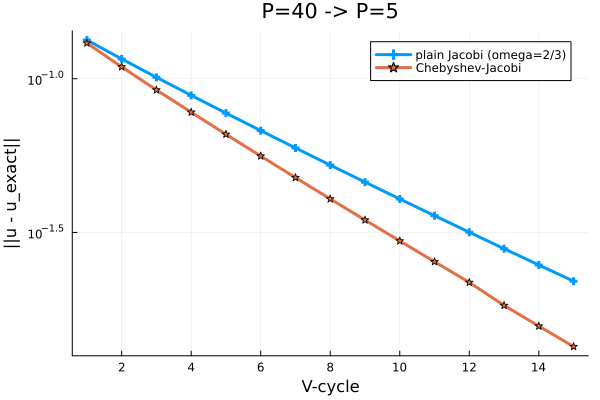

In [44]:
Pf2, Pc2 = 40, 5
A2, rhs2, x2 = general_galerkin_sym(Pf2, Pf2, kappa, f, "GAUSS")
u_exact2 = A2 \ rhs2

Icf2 = ProlongationMatrix(Pc2, Pf2)

u_plain = zeros(Pf2)
u_cheb = zeros(Pf2)
err_plain = Float64[]
err_cheb = Float64[]
for it in 1:15
    global u_plain = pmg_vcycle(A2, rhs2, u_plain, Icf2; nu1=2, nu2=2, omega=2/3)
    global u_cheb = pmg_vcycle_cheb(A2, rhs2, u_cheb, Icf2; nu1=2, nu2=2)
    push!(err_plain, norm(u_plain - u_exact2))
    push!(err_cheb, norm(u_cheb - u_exact2))
end
plot(err_plain, marker=:auto, yscale=:log10, label="plain Jacobi (omega=2/3)",
    xlabel="V-cycle", ylabel="||u - u_exact||", title="P=$Pf2 -> P=$Pc2")
plot!(err_cheb, marker=:star, label="Chebyshev-Jacobi")